<a href="https://colab.research.google.com/github/Sushant2007-srm/ML-Lab/blob/main/PCA_Questions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (178, 13)
Number of Features: 13
Number of Samples: 178
Wine Classes: ['class_0' 'class_1' 'class_2']

First 5 rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2

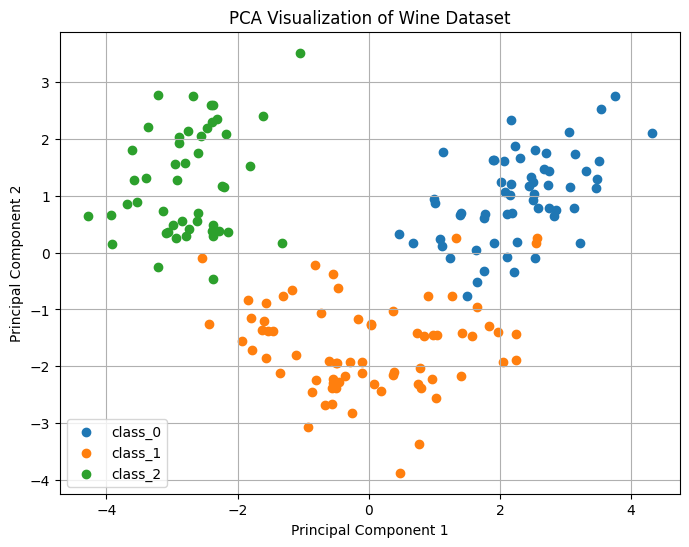


Question 1
Shape with 3 components: (178, 3)
Variance retained: 0.6652996889318523

Question 2
Variance ratio without standardization:
[0.99809123 0.00173592]

Question 3
1 components: Cumulative variance = 0.3619884809992633
2 components: Cumulative variance = 0.5540633835693526
3 components: Cumulative variance = 0.6652996889318523
5 components: Cumulative variance = 0.8016229275554786
10 components: Cumulative variance = 0.9616971684450643

Components needed for 90% variance: 8


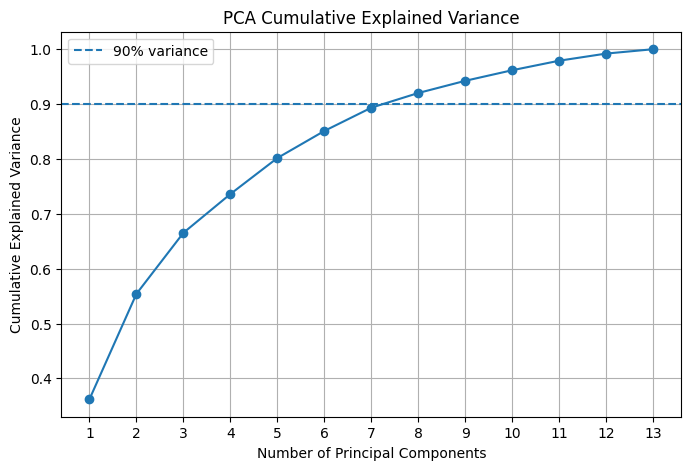


Question 5
Original Features:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

PCA Components:
[[ 0.1443294  -0.24518758 -0.00205106 -0.23932041  0.14199204  0.39466085
   0.4229343  -0.2985331   0.31342949 -0.0886167   0.29671456  0.37616741
   0.28675223]
 [ 0.48365155  0.22493093  0.31606881 -0.0105905   0.299634    0.06503951
  -0.00335981  0.02877949  0.03930172  0.52999567 -0.27923515 -0.16449619
   0.36490283]]


In [ ]:

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load Wine dataset
wine = load_wine()

# Store features and target
X = wine.data
y = wine.target

# Display dataset information
print("Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])
print("Number of Samples:", X.shape[0])
print("Wine Classes:", wine.target_names)

# Convert features into a DataFrame
df = pd.DataFrame(X, columns=wine.feature_names)
df["Target"] = y

print("\nFirst 5 rows:")
print(df.head())

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA with 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\nShape after PCA:", X_pca.shape)

# Explained variance ratio
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")
print(pca.explained_variance_ratio_.sum())

# Plot first two principal components
plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(wine.target_names):
    plt.scatter(
        X_pca[y == class_id, 0],
        X_pca[y == class_id, 1],
        label=class_name
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Wine Dataset")
plt.legend()
plt.grid(True)
plt.show()

# Question 1: Change number of components to 3
pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

print("\nQuestion 1")
print("Shape with 3 components:", X_pca3.shape)
print("Variance retained:", pca3.explained_variance_ratio_.sum())

# Question 2: PCA without standardization
pca_original = PCA(n_components=2)
X_original_pca = pca_original.fit_transform(X)

print("\nQuestion 2")
print("Variance ratio without standardization:")
print(pca_original.explained_variance_ratio_)

# Question 3: Try different component numbers
print("\nQuestion 3")

for n in [1, 2, 3, 5, 10]:
    pca_temp = PCA(n_components=n)
    pca_temp.fit(X_scaled)

    print(
        n,
        "components:",
        "Cumulative variance =",
        pca_temp.explained_variance_ratio_.sum()
    )

# Find components needed for 90% variance
pca_all = PCA()
pca_all.fit(X_scaled)

cumulative_variance = np.cumsum(
    pca_all.explained_variance_ratio_
)

components_90 = np.argmax(
    cumulative_variance >= 0.90
) + 1

print("\nComponents needed for 90% variance:",
      components_90)

# Plot cumulative explained variance
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 14),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.xticks(range(1, 14))
plt.grid(True)
plt.legend()
plt.show()

# Question 4: Visualization is already plotted above

# Question 5: Display original feature names
print("\nQuestion 5")
print("Original Features:")
print(wine.feature_names)

print("\nPCA Components:")
print(pca.components_)
